<a href="https://colab.research.google.com/github/donjperpetua/ML_ENG_HW1/blob/main/ML_ENG_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Donald Perpetua | RIN: 662040925

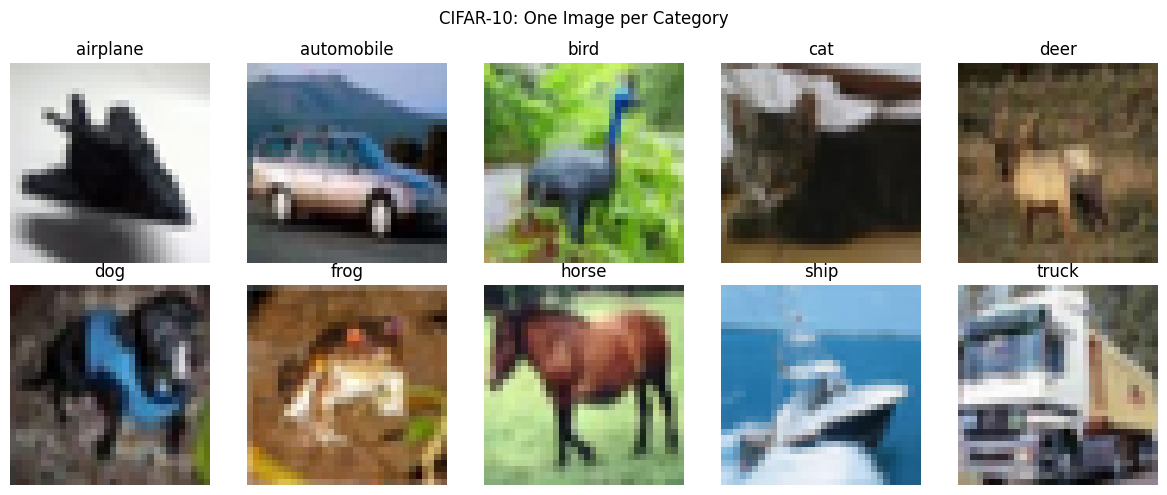

Training samples: 35000
Validation samples: 15000
Test samples: 10000
Input features: 3072


In [3]:
#Problem 1

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split, ParameterGrid


# Load CIFAR-10
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

y_all = y_all.ravel()
y_test = y_test.ravel()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
#plot one example from each category
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):
    image_index = np.where(y_all == class_id)[0][0]
    ax.imshow(x_all[image_index])
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.suptitle("CIFAR-10: One Image per Category")
plt.tight_layout()
plt.show()

#normalize pixel values between 0-1
x_all = x_all.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

#70-30 training-validation split
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=0.30,
    random_state=123,
    stratify=y_all
)

#flatten each 32 x 32 x 3 image into a 3072-dimensional vector
x_train = x_train.reshape(len(x_train), -1)
x_val = x_val.reshape(len(x_val), -1)
x_test = x_test.reshape(len(x_test), -1)

print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Test samples:", len(x_test))
print("Input features:", x_train.shape[1])

In [9]:

def build_model(num_layers, neurons, learning_rate):
    model = keras.Sequential()
    model.add(layers.Input(shape=(3072,)))

    for _ in range(num_layers):
        model.add(layers.Dense(neurons, activation="relu"))

    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [12]:

param_grid = {
    "num_layers": [1, 2, 3],
    "neurons": [256, 512],
    "learning_rate": [0.01, 0.005, 0.0001],
    "batch_size": [128, 256]
}

grid = list(ParameterGrid(param_grid))

results = []
histories = []
best_val_accuracy = -1
best_model = None
best_history = None
best_params = None

EPOCHS = 8

for i, params in enumerate(grid):
    print(f"\nConfiguration {i + 1}/{len(grid)}: {params}")

    tf.keras.backend.clear_session()
    tf.random.set_seed(123 + i)

    model = build_model(
        num_layers=params["num_layers"],
        neurons=params["neurons"],
        learning_rate=params["learning_rate"]
    )

    # restore the model weights from its best validation epoch
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=params["batch_size"],
        callbacks=[early_stopping],
        verbose=1
    )

    #best validation accuracy reached during this run
    best_epoch_index = np.argmax(history.history["val_accuracy"])
    run_best_val_accuracy = history.history["val_accuracy"][
        best_epoch_index
    ]

    run_best_val_loss = history.history["val_loss"][
        best_epoch_index
    ]

    results.append({
        "num_layers": params["num_layers"],
        "neurons": params["neurons"],
        "learning_rate": params["learning_rate"],
        "batch_size": params["batch_size"],
        "best_epoch": best_epoch_index + 1,
        "best_val_accuracy": run_best_val_accuracy,
        "best_val_loss": run_best_val_loss
    })

    histories.append(history.history)

    if run_best_val_accuracy > best_val_accuracy:
        best_val_accuracy = run_best_val_accuracy
        best_model = model
        best_history = history
        best_params = params.copy()




Configuration 1/36: {'batch_size': 128, 'learning_rate': 0.01, 'neurons': 256, 'num_layers': 1}
Epoch 1/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.0990 - loss: 3.5971 - val_accuracy: 0.1000 - val_loss: 2.3028
Epoch 2/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.0979 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3029
Epoch 3/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.0993 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3029
Epoch 4/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.0983 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3030

Configuration 2/36: {'batch_size': 128, 'learning_rate': 0.01, 'neurons': 256, 'num_layers': 2}
Epoch 1/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.2581 - loss: 2.6535 - val_accuracy: 0.3369 - val_loss: 1.8379
Epoch 2/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.3330 - loss: 1.8365 - val_accuracy: 0.3547 - val_loss: 1.8016
Epoch 3/8
274/274 ━━━━━━━━━━━━━━━━━━━


Grid-search results:
 num_layers  neurons  learning_rate  batch_size  best_epoch  best_val_accuracy  best_val_loss
          3      512         0.0001         128           8           0.481733       1.463939
          3      512         0.0001         256           8           0.478267       1.463270
          2      512         0.0001         256           8           0.474400       1.496679
          2      512         0.0001         128           8           0.470400       1.496855
          3      256         0.0001         128           8           0.468800       1.507391
          1      512         0.0001         128           8           0.466200       1.542136
          3      256         0.0001         256           8           0.456533       1.544033
          2      256         0.0001         128           8           0.454733       1.548650
          1      512         0.0001         256           8           0.454400       1.575240
          1      256         0.0001   

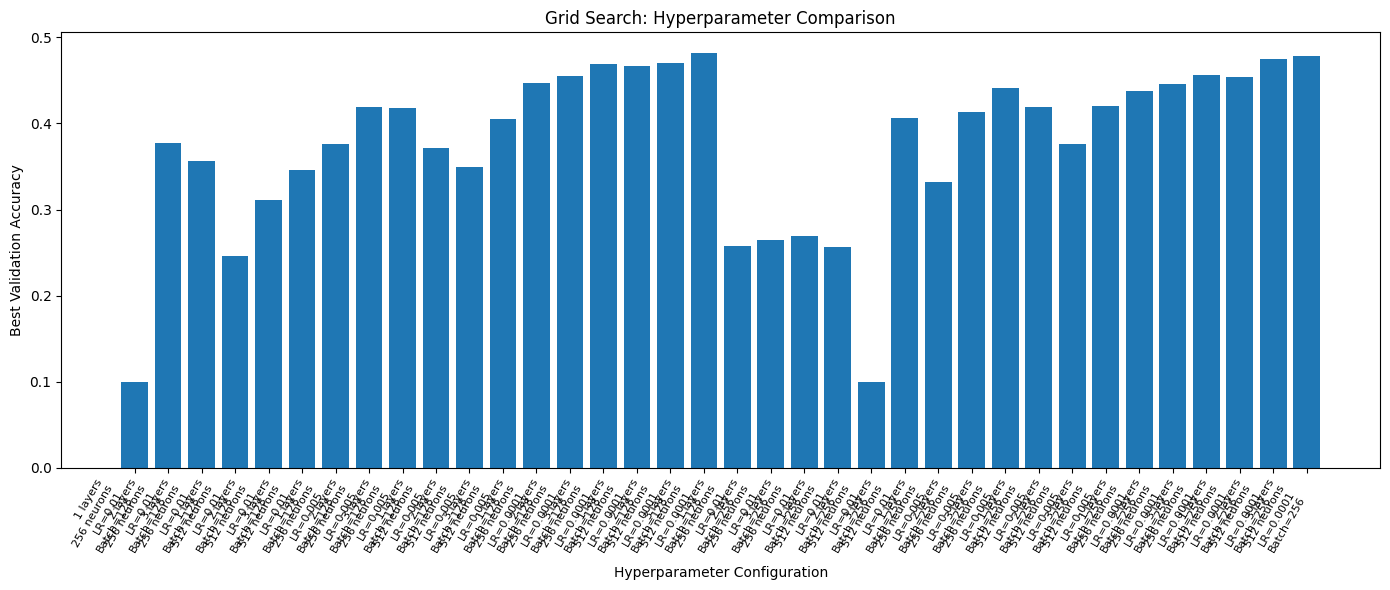

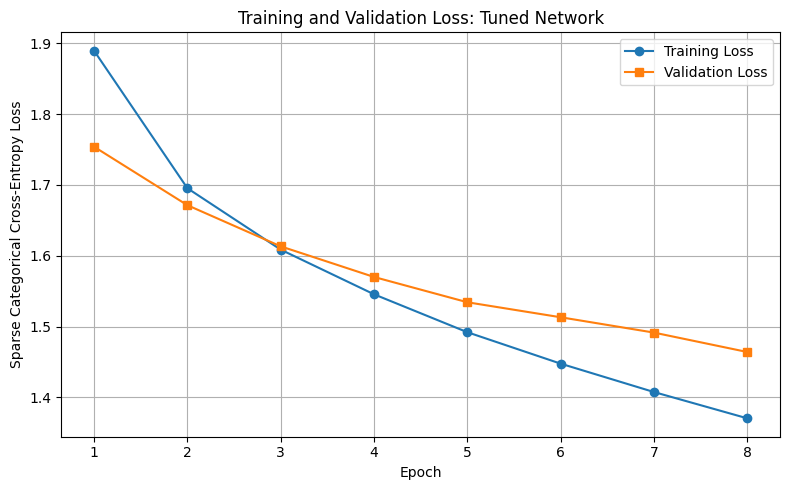

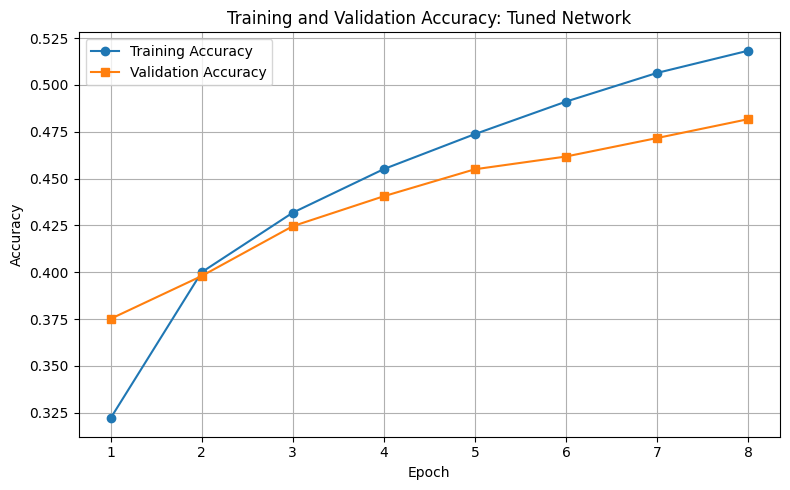

In [15]:

import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="best_val_accuracy",
    ascending=False
).reset_index(drop=True)

print("\nGrid-search results:")
print(results_df.to_string(index=False))

print("\nBest hyperparameters:")
print(best_params)
print(f"Best validation accuracy: {best_val_accuracy:.4f}")

plt.figure(figsize=(14, 6))

config_labels = [
    f"{p['num_layers']} layers\n"
    f"{p['neurons']} neurons\n"
    f"LR={p['learning_rate']}\n"
    f"Batch={p['batch_size']}"
    for p in grid
]

plt.bar(
    config_labels,
    [max(h["val_accuracy"]) for h in histories]
)

plt.ylabel("Best Validation Accuracy")
plt.xlabel("Hyperparameter Configuration")
plt.title("Grid Search: Hyperparameter Comparison")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

history = best_history.history
epochs = range(1, len(history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["loss"], marker="o",
         label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="s",
         label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Cross-Entropy Loss")
plt.title("Training and Validation Loss: Tuned Network")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(epochs, history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="s",
         label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy: Tuned Network")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


   Frequency  Angle of Attack  Chord Length  Free-stream Velocity  \
0        800              0.0        0.3048                  71.3   
1       1000              0.0        0.3048                  71.3   
2       1250              0.0        0.3048                  71.3   
3       1600              0.0        0.3048                  71.3   
4       2000              0.0        0.3048                  71.3   

   Displacement Thickness  Sound Pressure Level  
0                0.002663               126.201  
1                0.002663               125.201  
2                0.002663               125.951  
3                0.002663               127.591  
4                0.002663               127.461  
(1503, 6)
          Frequency  Angle of Attack  Chord Length  Free-stream Velocity  \
count   1503.000000      1503.000000   1503.000000           1503.000000   
mean    2886.380572         6.782302      0.136548             50.860745   
std     3152.573137         5.918128      0.093

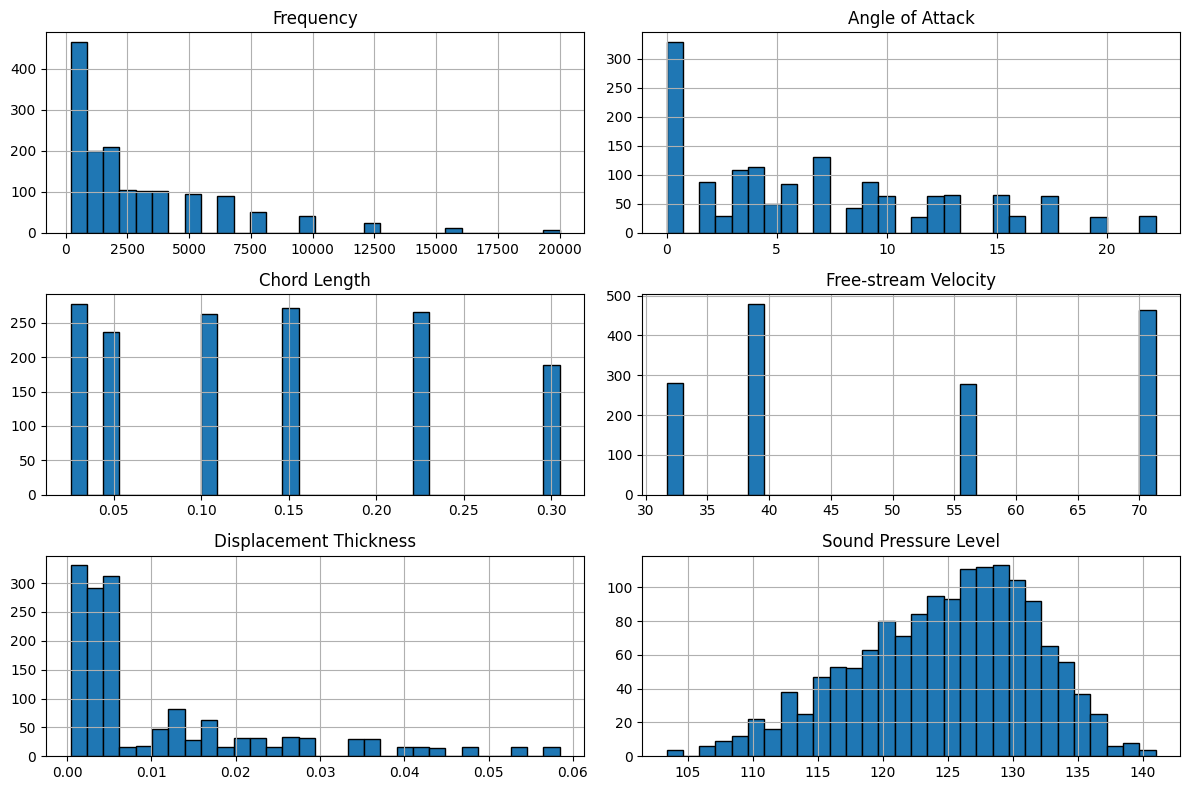

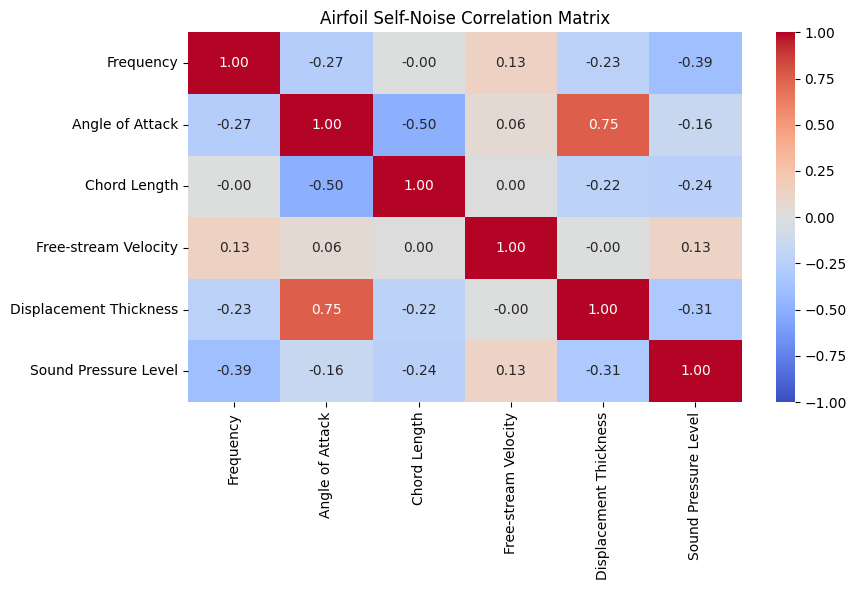

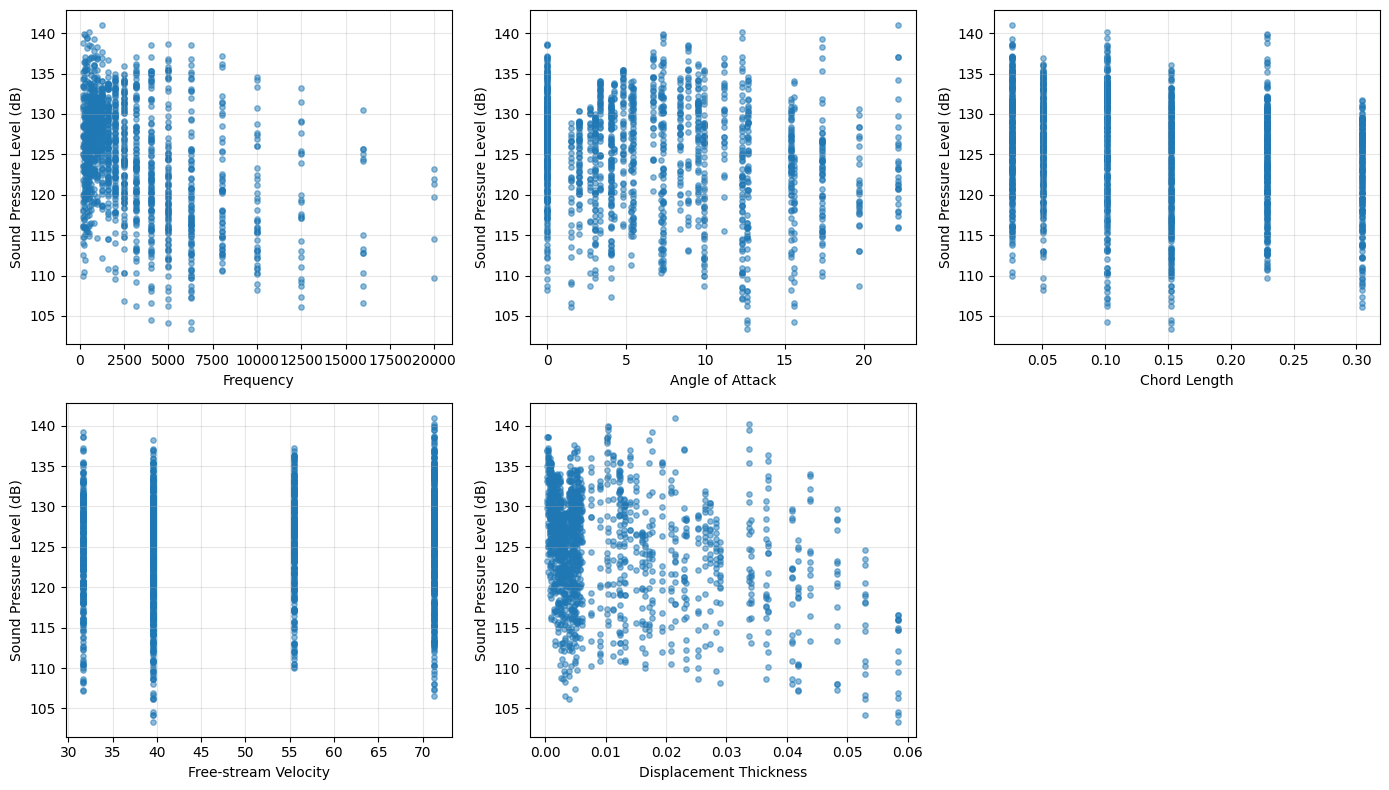

In [5]:
# Problem 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00291/"
    "airfoil_self_noise.dat"
)

columns = [
    "Frequency",
    "Angle of Attack",
    "Chord Length",
    "Free-stream Velocity",
    "Displacement Thickness",
    "Sound Pressure Level"
]

df = pd.read_csv(url, sep=r"\s+", header=None, names=columns)

# Inspect dataset
print(df.head())
print(df.shape)
print(df.describe())
print(df.isnull().sum())


df.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

#correlation matrix
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)
plt.title("Airfoil Self-Noise Correlation Matrix")
plt.tight_layout()
plt.show()

#input vs output plot
features = columns[:-1]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].scatter(df[feature], df["Sound Pressure Level"],
                    alpha=0.5, s=15)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Sound Pressure Level (dB)")
    axes[i].grid(True, alpha=0.3)

axes[5].axis("off")
plt.tight_layout()
plt.show()

Training samples: 1052
Testing samples: 451


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 15375.9316 - mae: 123.7945 - val_loss: 15112.0078 - val_mae: 122.6938
Epoch 2/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 14771.6826 - mae: 121.3014 - val_loss: 14244.1270 - val_mae: 119.0469
Epoch 3/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 13633.9287 - mae: 116.4308 - val_loss: 12695.2803 - val_mae: 112.2024
Epoch 4/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 11722.9277 - mae: 107.7175 - val_loss: 10303.3398 - val_mae: 100.6041
Epoch 5/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 8980.7383 - mae: 93.5966 - val_loss: 7214.1387 - val_mae: 82.9386
Epoch 6/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5816.5898 - mae: 73.4978 - val_loss: 4149.1504 - val_mae: 60.6239
Epoch 7/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 3082.9219 - mae: 50.7819 - val_loss: 2009.0587 - val_mae: 40.0519
Epoch 8/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 1447.8041 - mae: 33.3114 - val_loss: 1007.

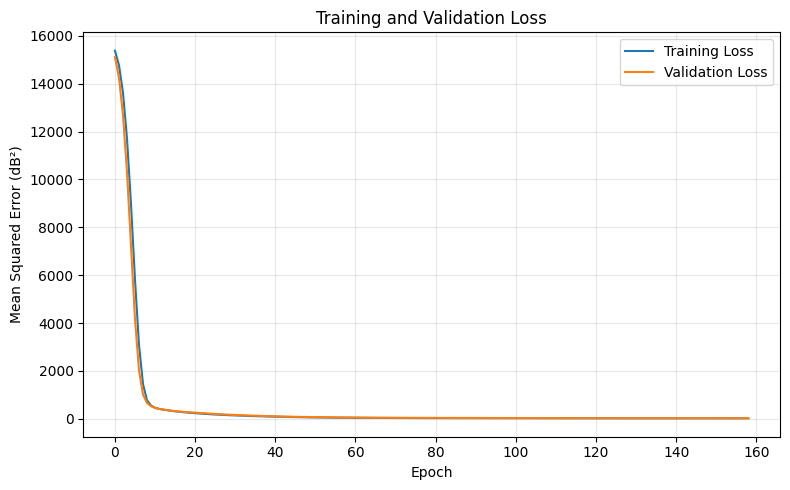

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

#Features
#Frequency, in Hz.
#Angle of attack, in degrees.
#Chord length, in meters.
#Free-stream velocity, in meters per second.
#Suction side displacement thickness, in meters.
X = df[columns[:-1]].values
#Target: Sound pressure (dB)
y = df["Sound Pressure Level"].values

#70/30 testing-training split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

#Standardize inputs
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#fully connected neural network
model = Sequential([
    Input(shape=(5,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

#training
history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.15,
    verbose=1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True
        )
    ]
)

#plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (dB²)")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test R-squared: 0.5479
Test MSE:       21.3444
Test RMSE:      4.6200 dB


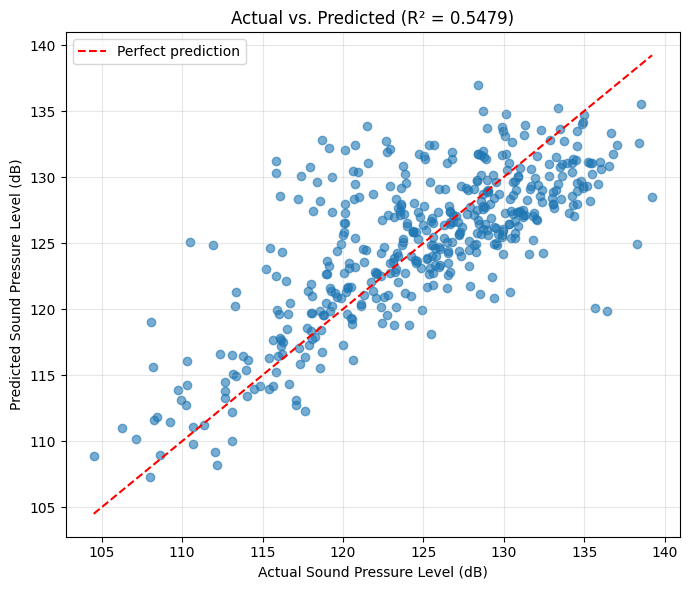

In [7]:
#predict test set
y_pred = model.predict(X_test).ravel()

#calc coefficient of determination and errors
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Test R-squared: {r2:.4f}")
print(f"Test MSE:       {mse:.4f}")
print(f"Test RMSE:      {rmse:.4f} dB")

#plot actual vs. predicted values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title(f"Actual vs. Predicted (R² = {r2:.4f})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()